Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Dataset shape: (150, 4)


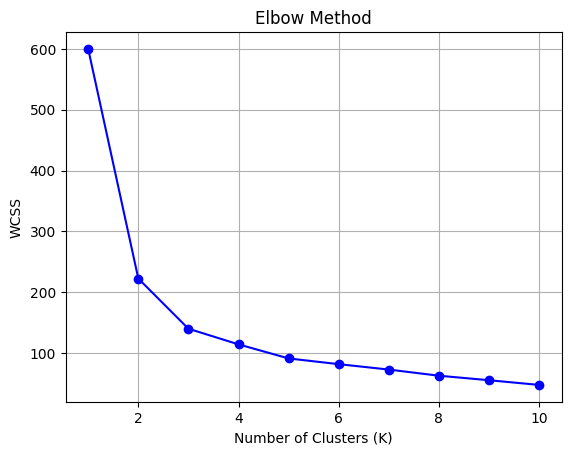


Cluster sizes:
0    53
1    50
2    47
Name: count, dtype: int64


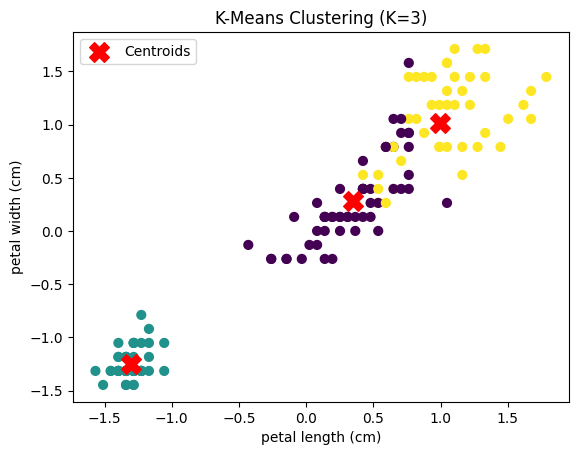

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load dataset
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)

print("Dataset:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

print("\nDataset shape:", X.shape)

# 2. Handle missing values
X = X.dropna()

# 3. Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, 'bo-')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid()
plt.show()

# 5. Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)

print("\nCluster sizes:")
print(pd.Series(clusters).value_counts().sort_index())

# 6. Visualize clusters
plt.scatter(
    X_scaled[:, 2],
    X_scaled[:, 3],
    c=clusters,
    cmap='viridis',
    s=40
)

plt.scatter(
    kmeans.cluster_centers_[:, 2],
    kmeans.cluster_centers_[:, 3],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel(X.columns[2])
plt.ylabel(X.columns[3])
plt.title("K-Means Clustering (K=3)")
plt.legend()
plt.show()

